In [ ]:
!pip install pymannkendall

import geemap
import ee
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from datetime import datetime
import pymannkendall as mk

In [ ]:
drive_files = [
    '/content/drive/MyDrive/rainfall_manual_daily_cwc_od_1961_1990.csv',
    '/content/drive/MyDrive/rainfall_manual_daily_odisha_od_1991_2020.csv',
    '/content/drive/MyDrive/rainfall_manual_daily_odisha_od_2021_2025.csv'
]
dataframes_list = [pd.read_csv(file_path) for file_path in drive_files]
climate_df = pd.concat(dataframes_list, ignore_index=True)


In [ ]:
dataframes_list = []

for file_path in drive_files:
    temp_df = pd.read_csv(file_path)
    dataframes_list.append(temp_df)

climate_df = pd.concat(dataframes_list, ignore_index=True)
print(climate_df.shape)

(128267, 20)


In [ ]:
climate_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128267 entries, 0 to 128266
Data columns (total 20 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   SlNo                        128267 non-null  int64  
 1   Station                     128267 non-null  object 
 2   Agency                      128267 non-null  object 
 3   State LGD Code              128267 non-null  int64  
 4   State                       128267 non-null  object 
 5   District LGD Code           128267 non-null  int64  
 6   District                    128267 non-null  object 
 7   Tehsil                      128267 non-null  object 
 8   Block                       128267 non-null  object 
 9   Village                     128267 non-null  object 
 10  River                       128267 non-null  object 
 11  Basin                       128267 non-null  object 
 12  Tributary                   128267 non-null  object 
 13  Subtributary  

In [ ]:
climate_df.describe()

,SlNo,State LGD Code,District LGD Code,Latitude,Longitude,Manual Daily Rainfall (mm)
count,128267.00000,128267.0,128267.000000,128267.000000,128267.000000,128267.000000
mean,35954.42438,21.0,359.597956,20.500832,84.732314,16.552429
std,25373.74662,0.0,8.636909,0.984733,1.392340,24.461837
min,1.00000,21.0,344.000000,18.493333,82.116389,0.010000
25%,14729.00000,21.0,353.000000,19.755556,83.727500,3.000000
50%,30762.00000,21.0,361.000000,20.468889,84.633333,8.200000
75%,56469.50000,21.0,366.000000,21.175000,86.014444,20.400000
max,88536.00000,21.0,373.000000,22.406667,87.320556,903.000000


In [ ]:
climate_df.drop_duplicates()

,SlNo,Station,Agency,State LGD Code,State,District LGD Code,District,Tehsil,Block,Village,River,Basin,Tributary,Subtributary,SubSubtributary,Local River,Latitude,Longitude,Data Acquisition Time,Manual Daily Rainfall (mm)
0,1,Akhuapada,CWC,21,Odisha,348,BHADRAK,BHADRAK,-,-,Baitarani,Brahmani and Baitarni,-,-,-,Baitarani,20.916944,86.279722,28-03-1974 08:30,53.9
1,2,Akhuapada,CWC,21,Odisha,348,BHADRAK,BHADRAK,-,-,Baitarani,Brahmani and Baitarni,-,-,-,Baitarani,20.916944,86.279722,30-03-1974 08:30,7.6
2,3,Akhuapada,CWC,21,Odisha,348,BHADRAK,BHADRAK,-,-,Baitarani,Brahmani and Baitarni,-,-,-,Baitarani,20.916944,86.279722,31-03-1974 08:30,4.6
3,4,Akhuapada,CWC,21,Odisha,348,BHADRAK,BHADRAK,-,-,Baitarani,Brahmani and Baitarni,-,-,-,Baitarani,20.916944,86.279722,27-04-1974 08:30,10.2
4,5,Akhuapada,CWC,21,Odisha,348,BHADRAK,BHADRAK,-,-,Baitarani,Brahmani and Baitarni,-,-,-,Baitarani,20.916944,86.279722,12-05-1974 08:30,10.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
128262,2606,Tulaghat,Odisha,21,Odisha,358,KALAHANDI,MADANPUR RAMPUR,-,-,Mahanadi,Mahanadi,Roul,-,-,Roul,20.322222,83.613056,02-10-2021 08:30,32.4
128263,2607,Tulaghat,Odisha,21,Odisha,358,KALAHANDI,MADANPUR RAMPUR,-,-,Mahanadi,Mahanadi,Roul,-,-,Roul,20.322222,83.613056,05-10-2021 08:30,21.8
128264,2608,Tulaghat,Odisha,21,Odisha,358,KALAHANDI,MADANPUR RAMPUR,-,-,Mahanadi,Mahanadi,Roul,-,-,Roul,20.322222,83.613056,15-10-2021 08:30,38.6
128265,2609,Tulaghat,Odisha,21,Odisha,358,KALAHANDI,MADANPUR RAMPUR,-,-,Mahanadi,Mahanadi,Roul,-,-,Roul,20.322222,83.613056,17-10-2021 08:30,7.4


In [ ]:
climate_df.shape

(128267, 20)

In [ ]:
climate_df['DateTime'] = pd.to_datetime(climate_df['Data Acquisition Time'], format='%d-%m-%Y %H:%M', errors='coerce')
climate_df['Year'] = climate_df['DateTime'].dt.year
climate_df['Month'] = climate_df['DateTime'].dt.month
display(climate_df[['DateTime', 'Year', 'Month', 'Station', 'District', 'Manual Daily Rainfall (mm)']].head())

Missing values after date parsing:
DateTime                      0
Manual Daily Rainfall (mm)    0
dtype: int64


,DateTime,Year,Month,Station,District,Manual Daily Rainfall (mm)
0,1974-03-28 08:30:00,1974,3,Akhuapada,BHADRAK,53.9
1,1974-03-30 08:30:00,1974,3,Akhuapada,BHADRAK,7.6
2,1974-03-31 08:30:00,1974,3,Akhuapada,BHADRAK,4.6
3,1974-04-27 08:30:00,1974,4,Akhuapada,BHADRAK,10.2
4,1974-05-12 08:30:00,1974,5,Akhuapada,BHADRAK,10.2


In [ ]:
clean_df = climate_df.dropna(subset=['DateTime', 'Manual Daily Rainfall (mm)'])


In [ ]:
clean_df = clean_df[clean_df['Manual Daily Rainfall (mm)'] >= 0]


In [46]:

district_annual_rain = clean_df.groupby(['Year', 'District'])['Manual Daily Rainfall (mm)'].sum().reset_index()

display(district_annual_rain.head(8))



,Year,District,Manual Daily Rainfall (mm)
0,1970,KENDUJHAR,893.00
1,1971,KENDUJHAR,1349.80
2,1972,CUTTACK,1058.30
3,1972,KENDUJHAR,978.35
4,1972,SUNDARGARH,48.10
5,1973,CUTTACK,1699.60
6,1973,KENDUJHAR,2219.00
7,1973,PURI,1828.50


In [ ]:
for dis in climate_df['District'].unique():
  print(dis)

BHADRAK
JAGATSINGHAPUR
KENDUJHAR
MAYURBHANJ
SUNDARGARH
Baleshwar
RAYAGADA
JAJAPUR
BAUDH
GAJAPATI
KALAHANDI
CUTTACK
PURI
Nabarangapur
JHARSUGUDA
GANJAM
ANUGUL
BALANGIR
NAYAGARH
BARGARH
KHORDHA
SAMBALPUR
DEBAGARH
KORAPUT
NUAPADA
KENDRAPARA
MALKANGIRI
SONAPUR
KANDHAMAL


In [48]:
clean_df['District'] = clean_df['District'].str.title().str.strip()
spelling_fixes = {
    'Anugul': 'Angul',
    'Nabarangapur': 'Nabarangpur',
    'Jajapur': 'Jajpur'
}

clean_df['District'] = clean_df['District'].replace(spelling_fixes)
print(sorted(clean_df['District'].unique()))


['Angul', 'Balangir', 'Baleshwar', 'Bargarh', 'Baudh', 'Bhadrak', 'Cuttack', 'Debagarh', 'Gajapati', 'Ganjam', 'Jagatsinghapur', 'Jajpur', 'Jharsuguda', 'Kalahandi', 'Kandhamal', 'Kendrapara', 'Kendujhar', 'Khordha', 'Koraput', 'Malkangiri', 'Mayurbhanj', 'Nabarangpur', 'Nayagarh', 'Nuapada', 'Puri', 'Rayagada', 'Sambalpur', 'Sonapur', 'Sundargarh']


In [49]:
ganjam_df = clean_df[clean_df['District'] == 'Ganjam'].copy()


In [55]:
ganjam_df.head()

,SlNo,Station,Agency,State LGD Code,State,District LGD Code,District,Tehsil,Block,Village,...,Subtributary,SubSubtributary,Local River,Latitude,Longitude,Data Acquisition Time,Manual Daily Rainfall (mm),DateTime,Year,Month
26925,26926,Purusottampur,CWC,21,Odisha,354,Ganjam,Purusottampur,-,-,...,-,-,Rushikulya,19.516667,84.883333,28-05-1980 08:30,55.16,1980-05-28 08:30:00,1980,5
26926,26927,Purusottampur,CWC,21,Odisha,354,Ganjam,Purusottampur,-,-,...,-,-,Rushikulya,19.516667,84.883333,06-06-1980 08:30,22.70,1980-06-06 08:30:00,1980,6
26927,26928,Purusottampur,CWC,21,Odisha,354,Ganjam,Purusottampur,-,-,...,-,-,Rushikulya,19.516667,84.883333,10-06-1980 08:30,27.50,1980-06-10 08:30:00,1980,6
26928,26929,Purusottampur,CWC,21,Odisha,354,Ganjam,Purusottampur,-,-,...,-,-,Rushikulya,19.516667,84.883333,12-06-1980 08:30,10.20,1980-06-12 08:30:00,1980,6
26929,26930,Purusottampur,CWC,21,Odisha,354,Ganjam,Purusottampur,-,-,...,-,-,Rushikulya,19.516667,84.883333,13-06-1980 08:30,17.70,1980-06-13 08:30:00,1980,6


In [56]:
ganjam_annual = ganjam_df.groupby('Year')['Manual Daily Rainfall (mm)'].sum().reset_index()


In [57]:
ganjam_annual = ganjam_annual.sort_values('Year')

In [58]:
print(f"Data available from year {ganjam_annual['Year'].min()} to {ganjam_annual['Year'].max()}.\n")
display(ganjam_annual)

Data available from year 1980 to 2021.



,Year,Manual Daily Rainfall (mm)
0,1980,2992.060
1,1981,2882.400
2,1982,2304.800
3,1983,3129.000
4,1984,2186.300
5,1985,2753.800
6,1986,3224.200
7,1987,2449.900
8,1988,2636.400
9,1989,2463.700


In [69]:
ganjam_results = mk.original_test(ganjam_annual['Manual Daily Rainfall (mm)'])

print(" MANN-KENDALL CLIMATE TREND TEST FOR GANJAM")
print(f"• Trend Detected: {ganjam_results.trend.upper()}")
print(f"• P-Value (Significance Level): {ganjam_results.p:.5f}")
print(f"• Sen's Slope (Rainfall change per year): {ganjam_results.slope:.3f} mm")


 MANN-KENDALL CLIMATE TREND TEST FOR GANJAM
• Trend Detected: NO TREND
• P-Value (Significance Level): 0.24958
• Sen's Slope (Rainfall change per year): 34.101 mm


In [63]:
most_rain_row = ganjam_annual.loc[ganjam_annual['Manual Daily Rainfall (mm)'].idxmax()]
least_rain_row = ganjam_annual.loc[ganjam_annual['Manual Daily Rainfall (mm)'].idxmin()]

print(f" Most Rainfall Year: {int(most_rain_row['Year'])} with {most_rain_row['Manual Daily Rainfall (mm)']:.2f} mm")
print(f" Least Rainfall Year: {int(least_rain_row['Year'])} with {least_rain_row['Manual Daily Rainfall (mm)']:.2f} mm")

 Most Rainfall Year: 2001 with 7831.58 mm
 Least Rainfall Year: 2021 with 1347.12 mm


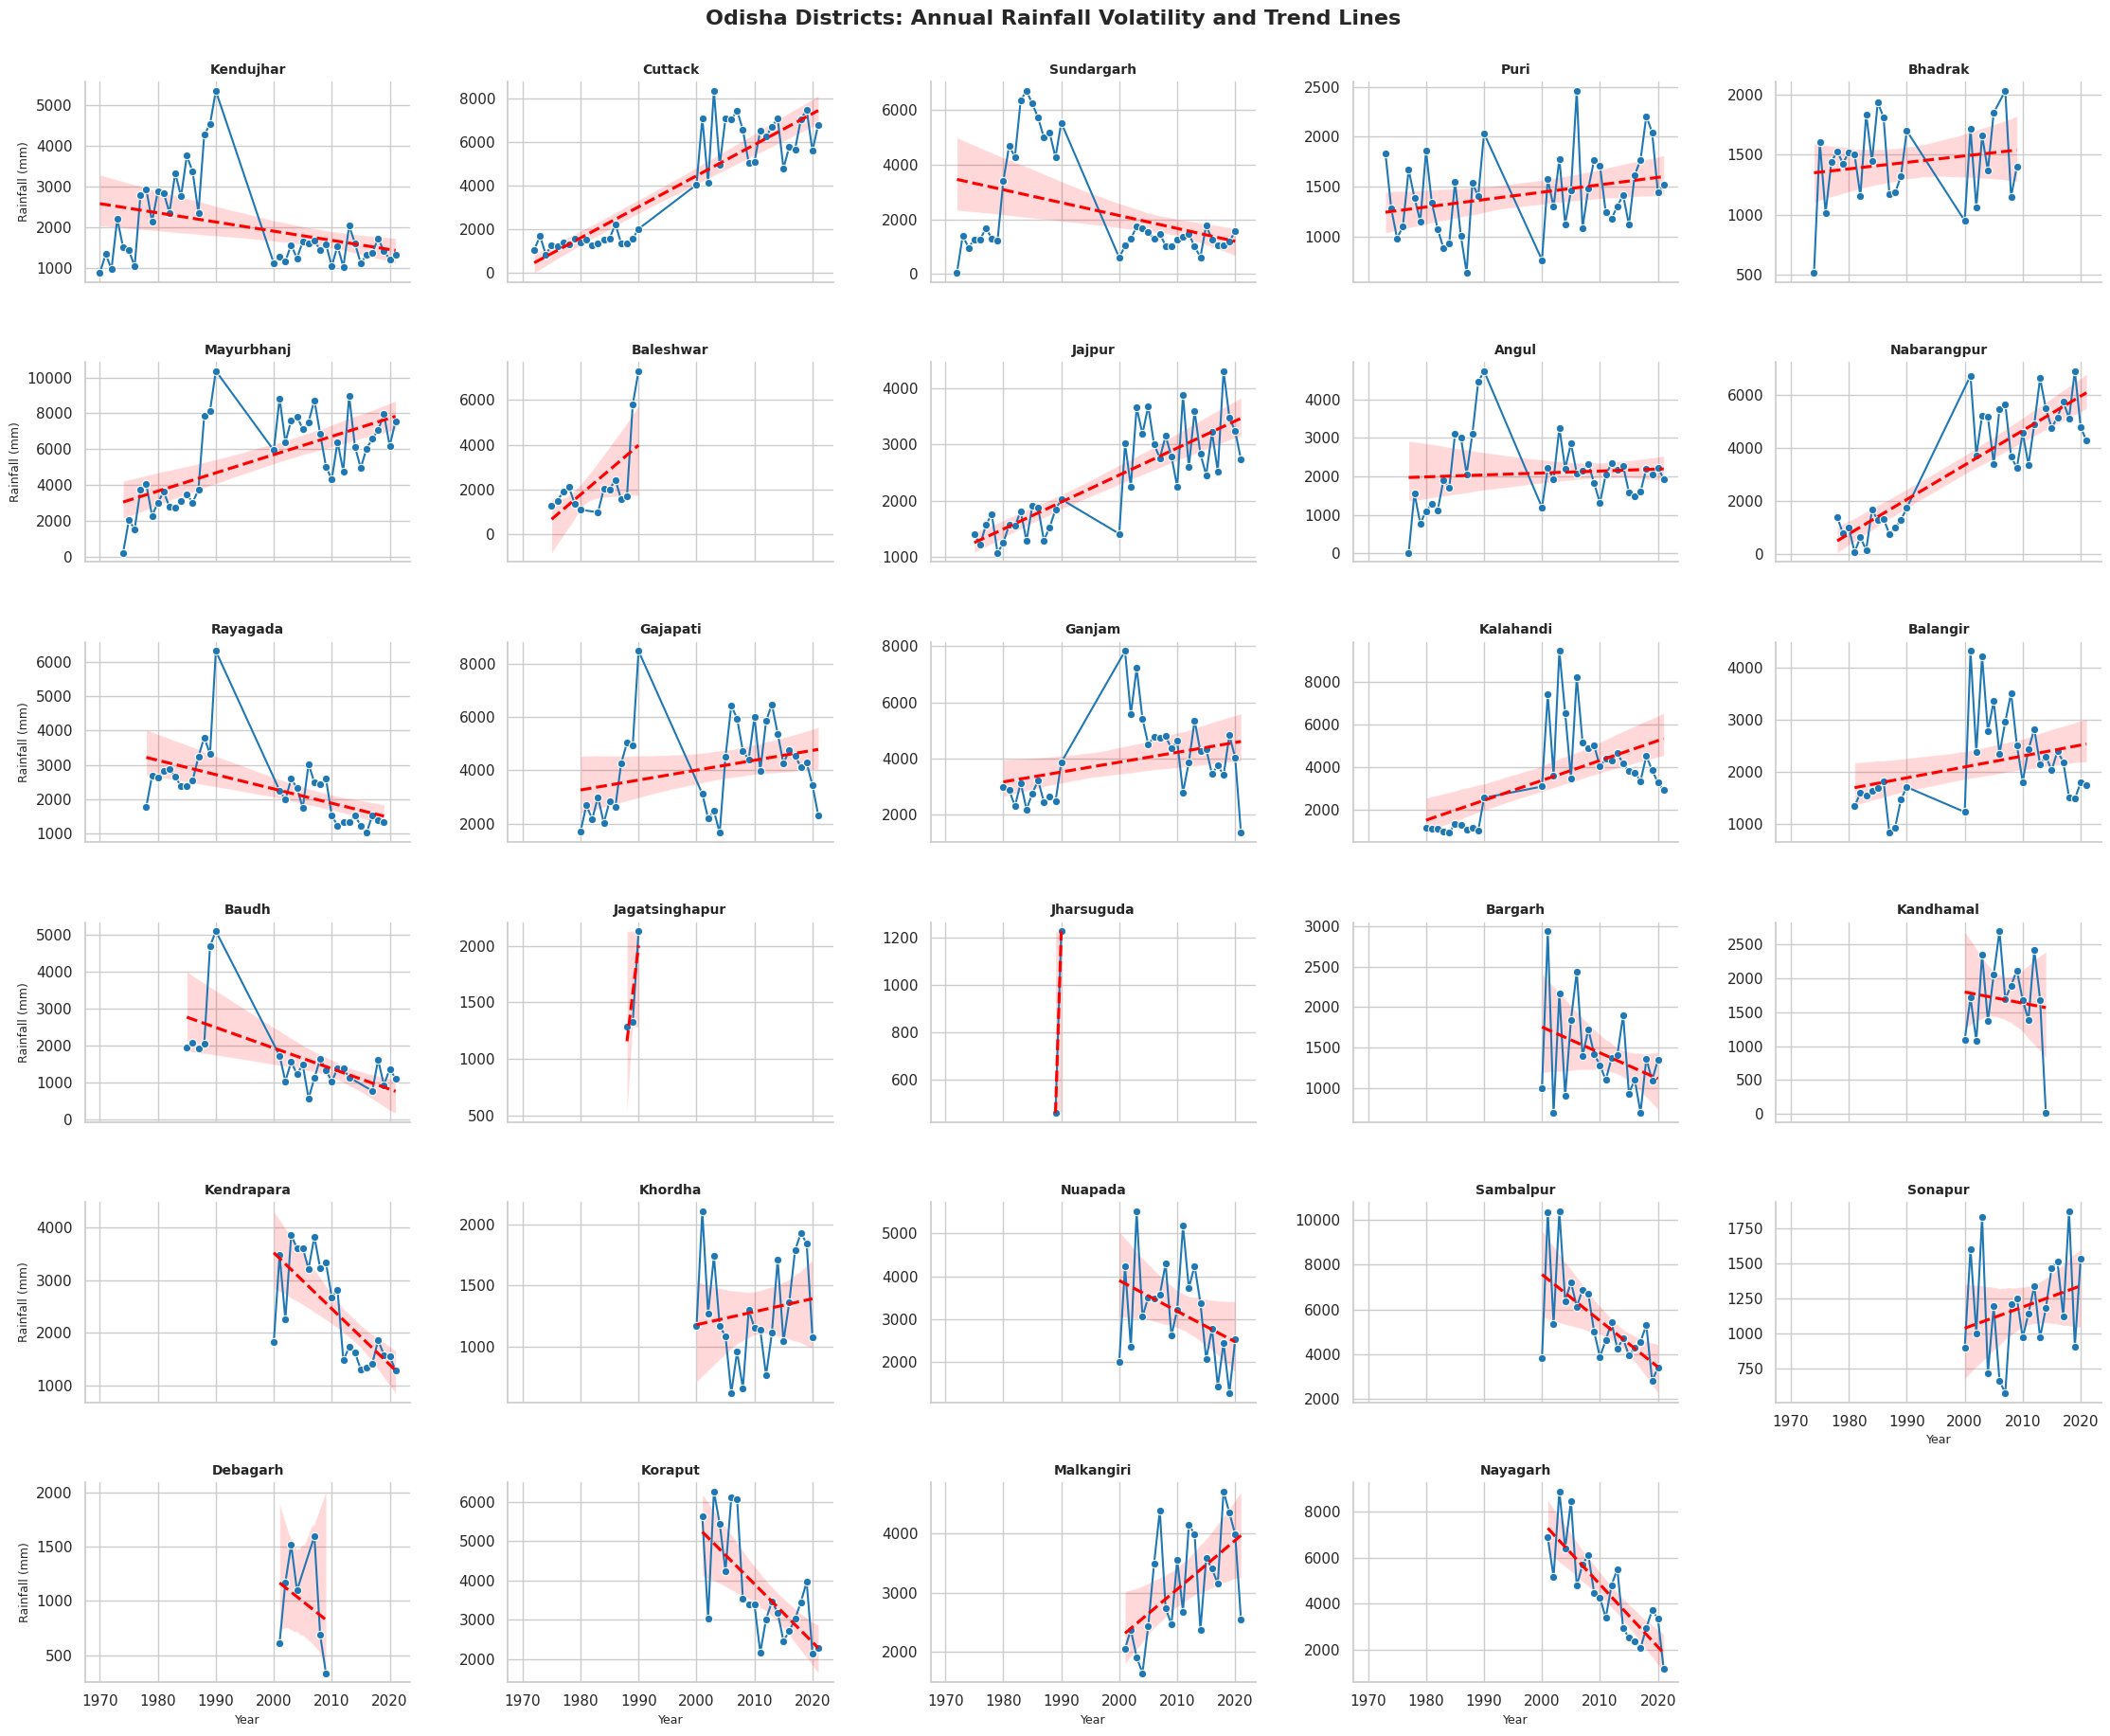

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
g = sns.FacetGrid(
    all_districts_annual,
    col="District",
    col_wrap=5,
    sharey=False,
    height=3,
    aspect=1.5
)
g.map_dataframe(sns.lineplot, x="Year", y="total_rain", color="#1f77b4", marker="o", linewidth=1.5)
g.map_dataframe(sns.regplot, x="Year", y="total_rain", scatter=False, color="red", line_kws={"linestyle": "--"})
g.set_titles("{col_name}", fontweight="bold", size=10)
g.set_axis_labels("Year", "Rainfall (mm)", size=9)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.suptitle("Odisha Districts: Annual Rainfall Volatility and Trend Lines", y=1.02, fontsize=16, fontweight="bold")

plt.show()

In [70]:

print(" Ingesting raw files from Google Drive...")

drive_files = [
    '/content/drive/MyDrive/rainfall_manual_daily_cwc_od_1961_1990.csv',
    '/content/drive/MyDrive/rainfall_manual_daily_odisha_od_1991_2020.csv',
    '/content/drive/MyDrive/rainfall_manual_daily_odisha_od_2021_2025.csv'
]

dataframes_list = [pd.read_csv(file_path) for file_path in drive_files]
climate_df = pd.concat(dataframes_list, ignore_index=True)
print(" Running text standardization and date formatting...")
climate_df['DateTime'] = pd.to_datetime(climate_df['Data Acquisition Time'], format='%d-%m-%Y %H:%M', errors='coerce')
climate_df['Year'] = climate_df['DateTime'].dt.year
climate_df['Month'] = climate_df['DateTime'].dt.month

clean_df = climate_df.dropna(subset=['DateTime', 'Manual Daily Rainfall (mm)'])
clean_df = clean_df[clean_df['Manual Daily Rainfall (mm)'] >= 0].copy()

clean_df['District'] = clean_df['District'].str.title().str.strip()
spelling_fixes = {
    'Rayagadaagada': 'Rayagada',
    'Anugul': 'Angul',
    'Nabarangapur': 'Nabarangpur',
    'Jajapur': 'Jajpur'
}
clean_df['District'] = clean_df['District'].replace(spelling_fixes)
all_districts_annual = clean_df.groupby(['Year', 'District']).agg(
    total_rain=('Manual Daily Rainfall (mm)', 'sum'),
    rainy_days=('Manual Daily Rainfall (mm)', lambda x: (x > 2.5).sum()), # Days > 2.5mm
    extreme_flood_days=('Manual Daily Rainfall (mm)', lambda x: (x >= 100.0).sum()) # Heavy Deluge Days
).reset_index()
all_districts_annual['storm_intensity'] = (
    all_districts_annual['total_rain'] / all_districts_annual['rainy_days']
).round(2)
print(" Executing statistical trend engine for all 29 districts")

trend_records = []
for district in all_districts_annual['District'].unique():
    district_data = all_districts_annual[all_districts_annual['District'] == district].sort_values('Year')

    # Process districts with robust timelines
    if len(district_data) >= 10:
        res = mk.original_test(district_data['total_rain'])
        trend_records.append({
            'District': district,
            'mk_trend': res.trend.upper(),
            'p_value': round(res.p, 5),
            'sens_slope': round(res.slope, 3)
        })

df_trends = pd.DataFrame(trend_records)
powerbi_master_df = pd.merge(all_districts_annual, df_trends, on='District', how='left')

powerbi_master_df.to_csv("odisha_climate_powerbi_master.csv", index=False)

print(" PIPELINE COMPLETE!")
print(f"• Total Data Records Compiled: {len(powerbi_master_df):,}")
print(f"• Output File Generated: 'odisha_climate_powerbi_master.csv' is ready to download.")


 Ingesting raw files from Google Drive...
 Running text standardization and date formatting...
 Executing statistical trend engine for all 29 districts
 PIPELINE COMPLETE!
• Total Data Records Compiled: 753
• Output File Generated: 'odisha_climate_powerbi_master.csv' is ready to download.
